# Workforce Intelligence: Phase 4 Attrition Risk Modelling & Out-of-Sample Validation

This presentation notebook details the leakage-safe development, probability calibration, and out-of-sample holdout validation of attrition risk models developed on the IBM HR analytics dataset.

> [!IMPORTANT]
> **Decision Support Only:** The models developed here provide ranking and triage support for human HR professionals > and line managers. **NO automated adverse action** is permitted.

In [1]:
import json
import pandas as pd
from IPython.display import Image, display, Markdown

manifest = pd.read_csv('reports/phase4/figure_manifest.csv')
display(Markdown('### Phase 4 Figure Manifest'))
manifest[['figure_id', 'filename', 'title', 'plotted_data_sha256']]

### Phase 4 Figure Manifest

,figure_id,filename,title,plotted_data_sha256
0,FIG-15,fig15_precision_recall_curves.png,FIG-15: Precision-Recall Curves across Attriti...,7dd6067851fe0caf080c9ff856a0ca7980fdd27508b64e...
1,FIG-16,fig16_calibration_curves.png,FIG-16: Probability Reliability Diagram (Calib...,a96367cbdd8b46d5fdca0dcfbf2dfbed7ac56005261c30...
2,FIG-17,fig17_risk_tier_attrition.png,FIG-17: Holdout Attrition Yield Across Model-P...,7ad300fed19ea7ff9cb488a576c676060567f2f0bb09e4...
3,FIG-18,fig18_feature_odds_ratios.png,FIG-18: Top Predictors in Regularised Logistic...,f2e56f475ce507a62c55e3fcf4f0804e89e220ea801b3e...
4,FIG-19,fig19_hotspot_validation.png,FIG-19: Out-of-Sample Validation of Candidate ...,de8c073c0bef3b7e4c7bc486ebe6262f5d5ad7220be012...
5,FIG-20,fig20_demographic_fairness.png,FIG-20: Demographic Fairness Audit at Operatio...,d8ec31269277826cbade3d5378c61c3484b11583889ff1...


## 1. Cross-Validation Model Development & Feature Set Governance

- **Training Split**: $n = 1,176$ (190 departures, 16.16% baseline).
- **Evaluation Protocol**: Repeated Stratified 5-Fold Cross-Validation (3 repeats = 15 folds).
- **Feature Set Governance**: Set B (demographics excluded) was selected because Set A (demographics included) did not exceed the pre-specified materiality threshold (+0.0300 PR-AUC gain).

In [2]:
cv_metrics = pd.read_csv('reports/phase4/tables/cv_metrics.csv')
display(cv_metrics[['model', 'feature_set', 'cv_pr_auc_mean', 'cv_pr_auc_std', 'cv_roc_auc_mean', 'cv_brier_score_mean']])

,model,feature_set,cv_pr_auc_mean,cv_pr_auc_std,cv_roc_auc_mean,cv_brier_score_mean
0,Dummy (Prior),B,0.161565,0.000284,0.500000,0.135462
1,HistGradientBoosting,B,0.530480,0.051543,0.785190,0.108979
2,Logistic Regression,A,0.655521,0.066654,0.836704,0.091225
3,Logistic Regression,B,0.630424,0.061760,0.830275,0.094921


## 2. Out-of-Sample Holdout Performance ($n = 294$, 47 Departures)

The holdout set was locked and scored exactly once at the conclusion of model development. Uncertainty intervals are 2,000-sample percentile bootstrap 95% confidence intervals.

In [3]:
holdout_df = pd.read_csv('reports/phase4/tables/holdout_metrics.csv')
display(holdout_df[['model', 'pr_auc_point', 'pr_auc_ci95_low', 'pr_auc_ci95_high', 'recall_at_10_point', 'recall_at_20_point', 'brier_score_point']])

,model,pr_auc_point,pr_auc_ci95_low,pr_auc_ci95_high,recall_at_10_point,recall_at_20_point,brier_score_point
0,Dummy (Prior),0.159864,0.119048,0.200680,0.085106,0.212766,0.134310
1,HistGradientBoosting,0.508423,0.371036,0.647177,0.340426,0.531915,0.110974
2,Logistic Regression (Uncalibrated),0.573585,0.431477,0.703701,0.404255,0.574468,0.099472
3,Logistic Regression (Calibrated - Sigmoid),0.569025,0.425802,0.698591,0.382979,0.574468,0.100615


### FIG-15: Precision-Recall Curves across Attrition Risk Models

*Evaluates model precision across all recall thresholds on unseen holdout data. Calibrated Logistic Regression (Set B) achieves PR-AUC = 0.5690 vs chance baseline of 0.1599.*

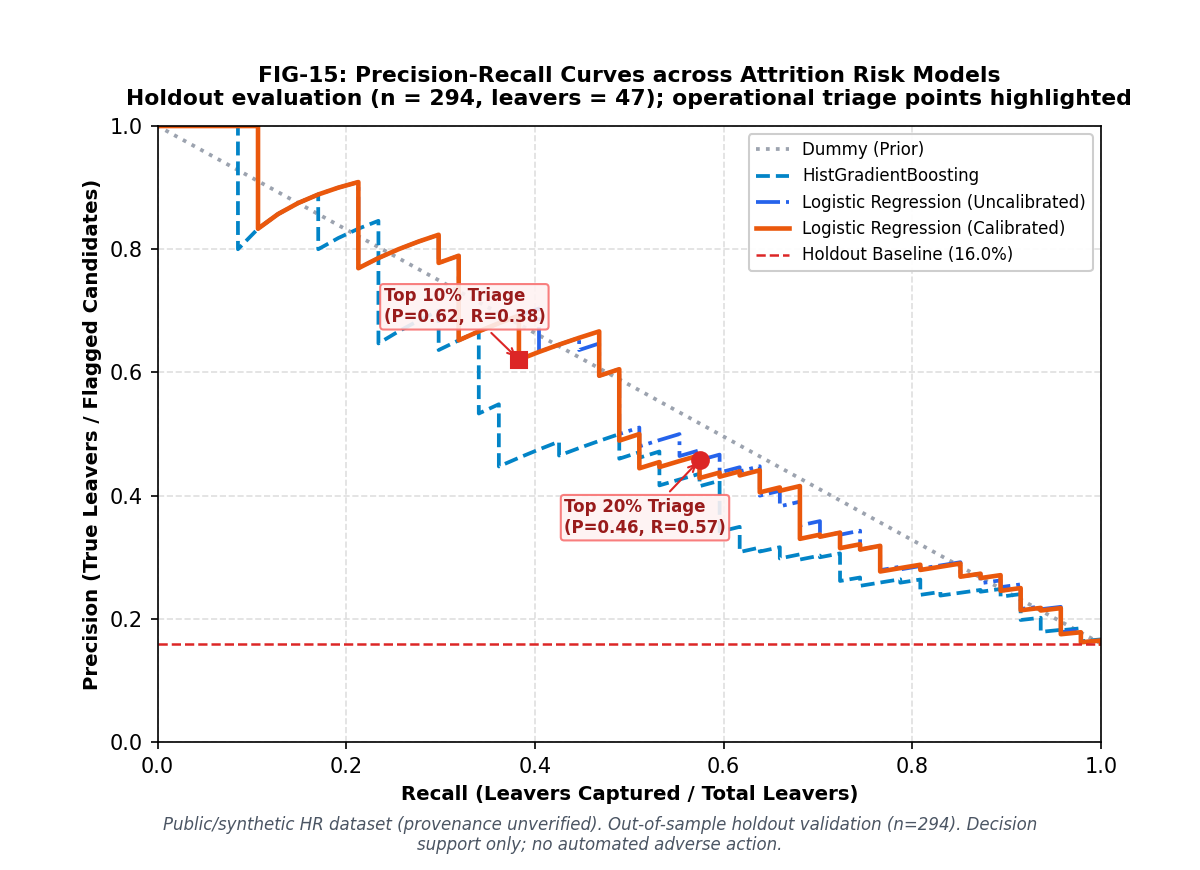

In [4]:
display(Image(filename='reports/phase4/figures/fig15_precision_recall_curves.png'))

### FIG-16: Probability Reliability Diagram (Calibration Curve)

*Demonstrates the effect of Platt/Sigmoid probability scaling. Calibrated probabilities align closely with empirical departure frequencies across all 5 risk bins.*

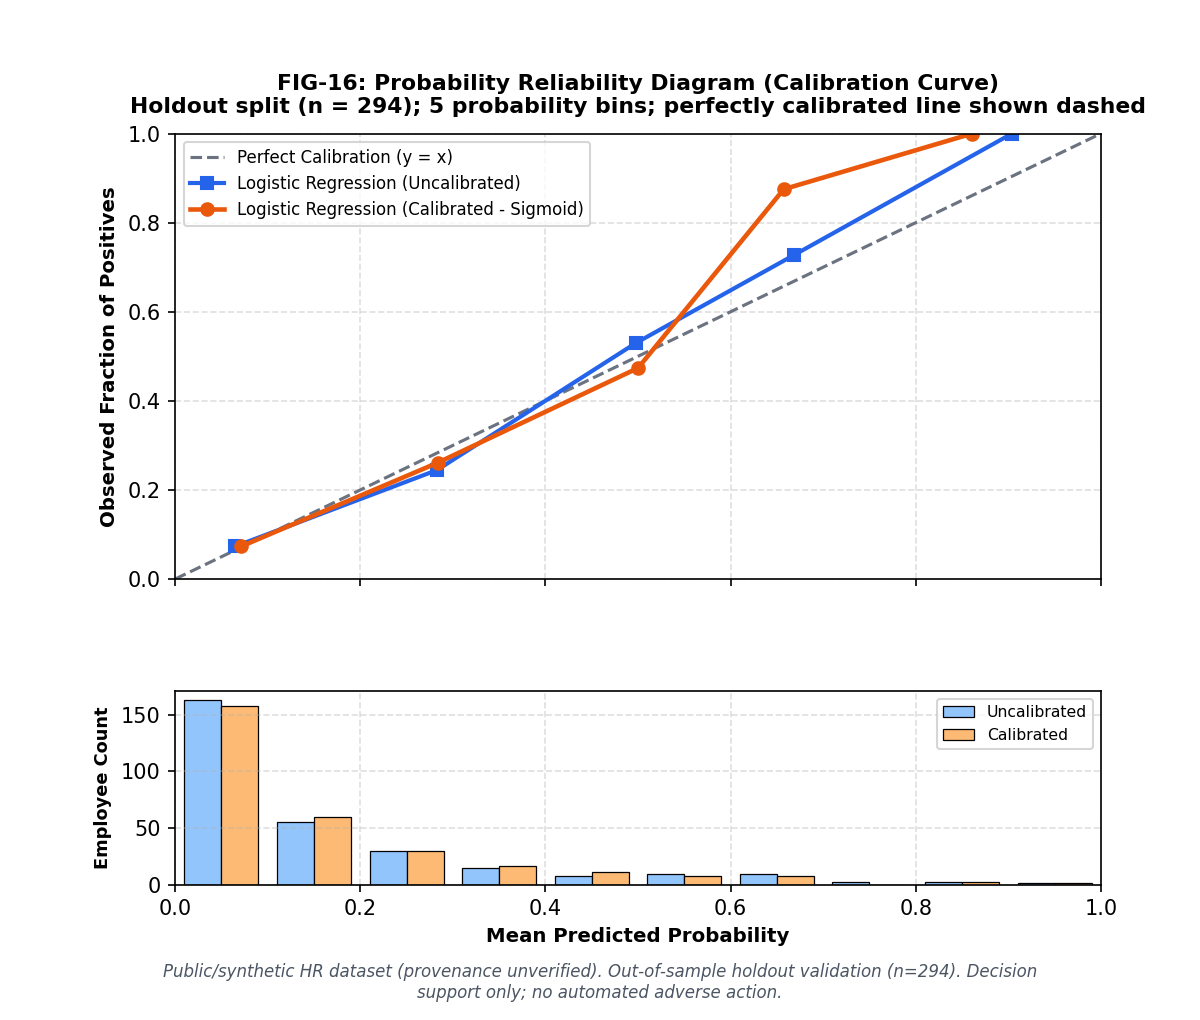

In [5]:
display(Image(filename='reports/phase4/figures/fig16_calibration_curves.png'))

### FIG-17: Holdout Attrition Yield Across Prioritized Risk Tiers

*Partitions the holdout workforce into Top 10%, Next 10%, and Remaining 80%. The top 10% risk tier yields an observed departure rate of 65.5% (nearly 4x the baseline).*

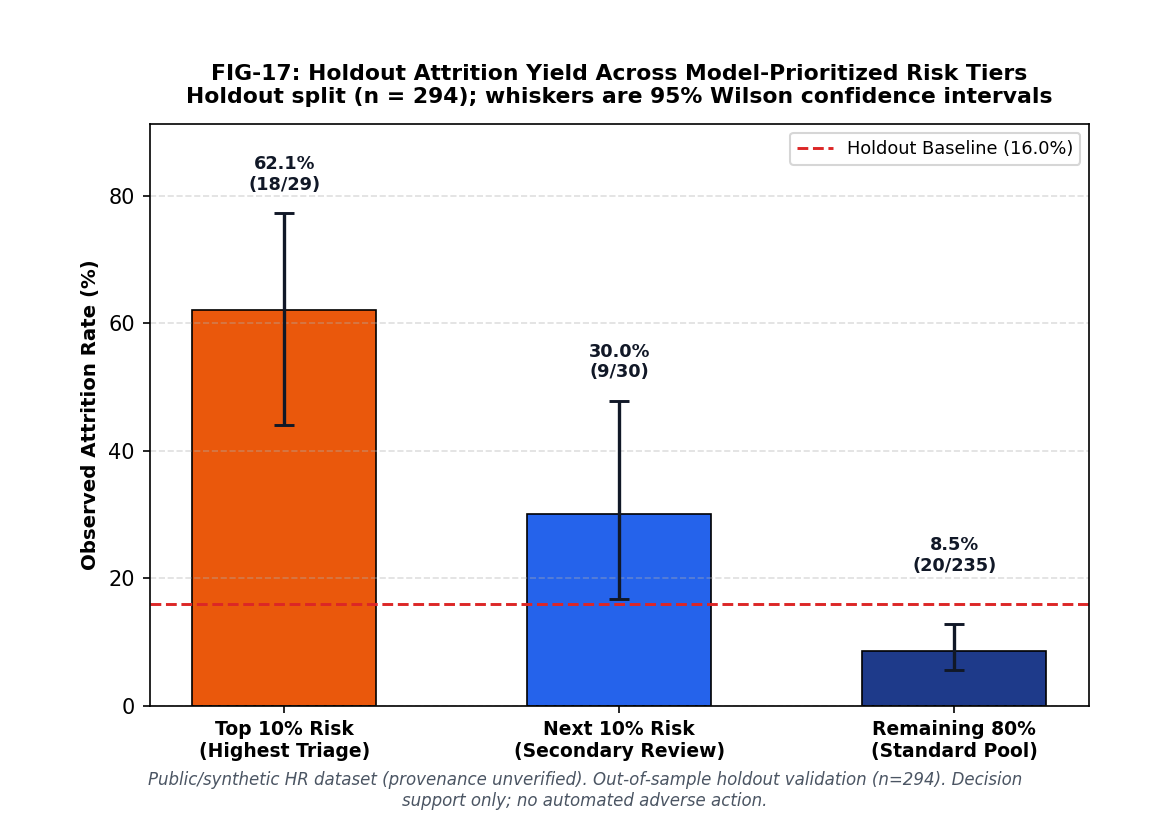

In [6]:
display(Image(filename='reports/phase4/figures/fig17_risk_tier_attrition.png'))

### FIG-18: Top Predictors in Regularised Logistic Regression

*Forest plot of standardized odds ratios with 95% confidence intervals. Overtime (OR = 2.00) and frequent business travel (OR = 1.73) dominate as operational risk factors.*

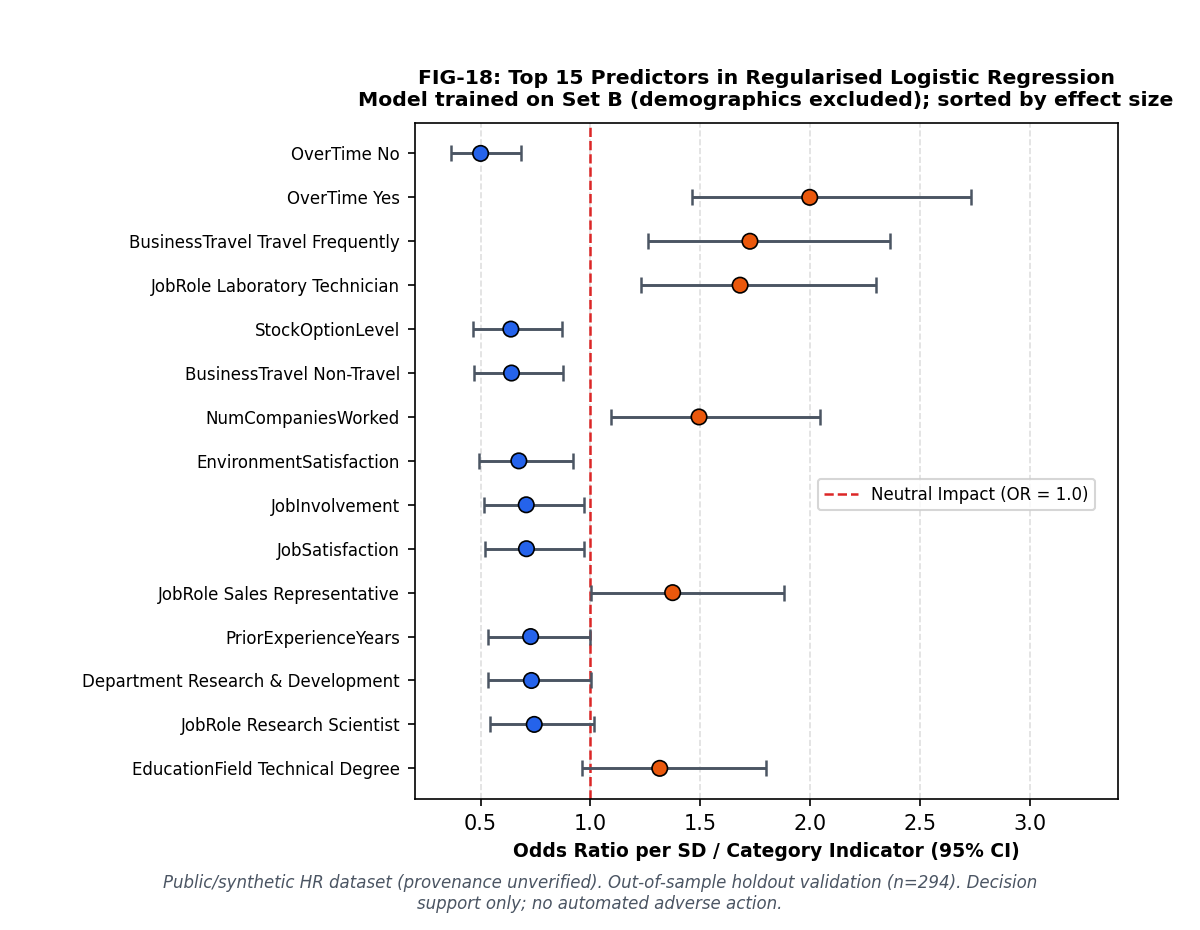

In [7]:
display(Image(filename='reports/phase4/figures/fig18_feature_odds_ratios.png'))

### FIG-19: Out-of-Sample Validation of Candidate Attrition Hotspots

*Compares training split rates to holdout split rates for screened candidate segments. Identifies segments that generalized out-of-sample vs those that faded or were underpowered in holdout.*

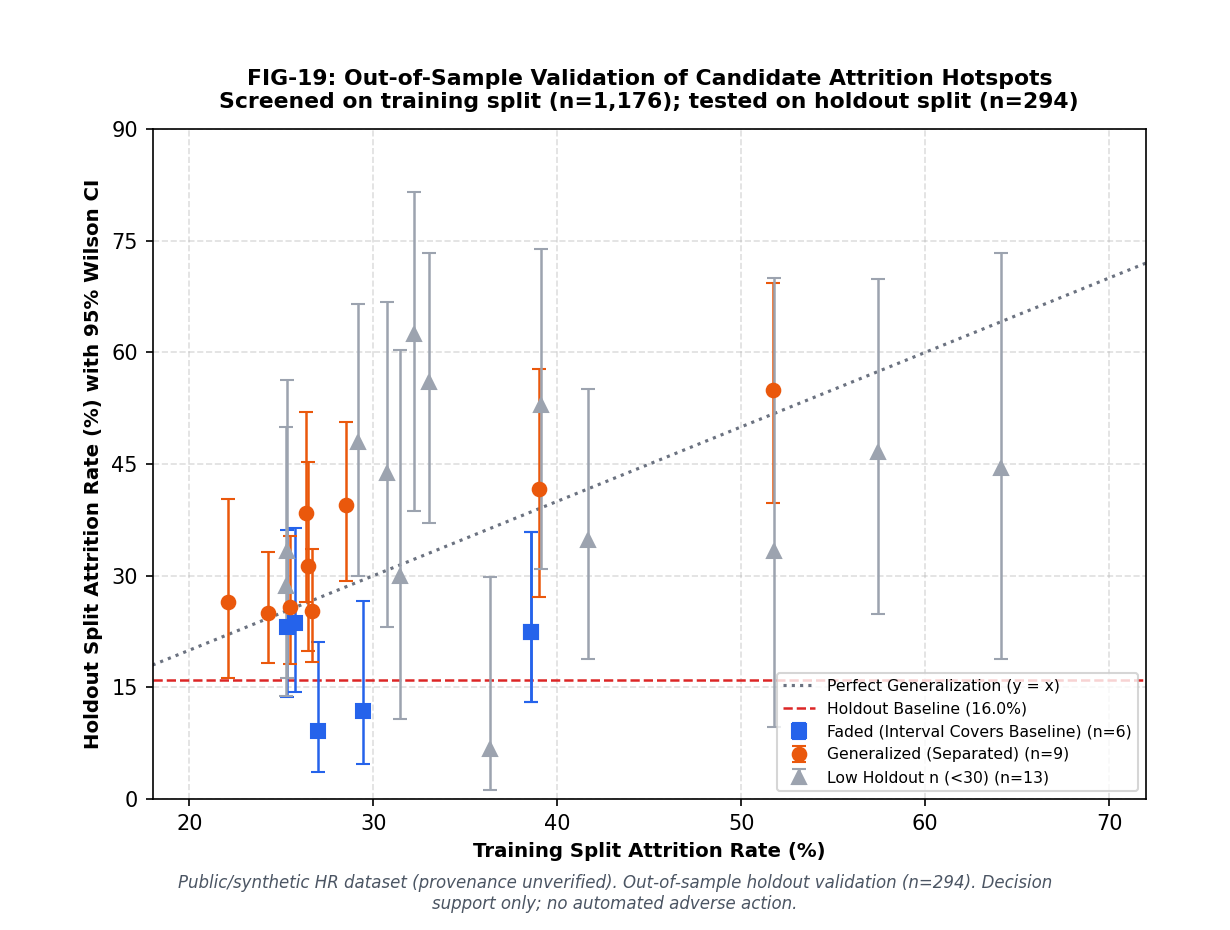

In [8]:
display(Image(filename='reports/phase4/figures/fig19_hotspot_validation.png'))

### FIG-20: Demographic Fairness Audit at Operational 20% Triage Threshold

*Audits model selection rate and leaver recall across Gender, MaritalStatus, and AgeGroup. Highlights disparate impact implications under the Four-Fifths rule in proactive support triage.*

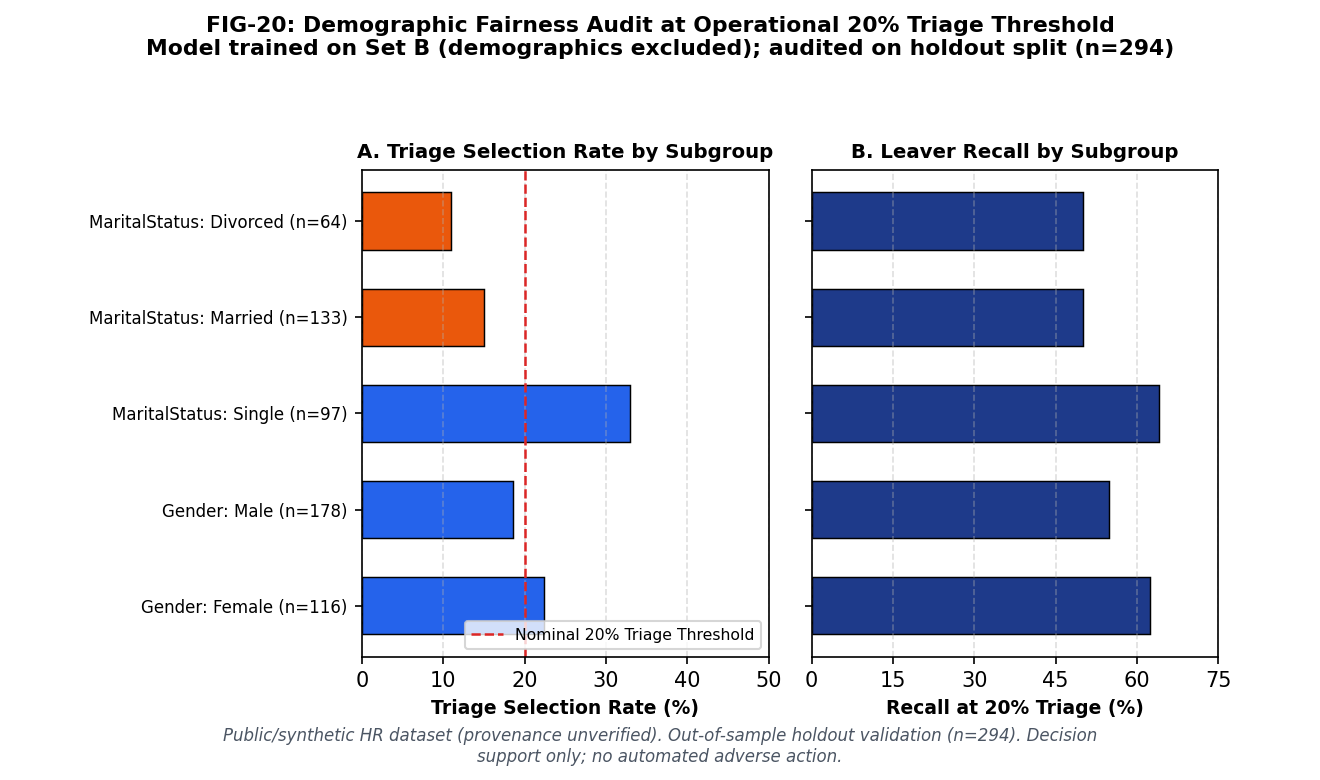

In [9]:
display(Image(filename='reports/phase4/figures/fig20_demographic_fairness.png'))

## 3. Hotspot Candidate Holdout Validation Summary Table

In [10]:
val_table = pd.read_csv('reports/phase4/tables/hotspot_validation.csv')
display(val_table[['segment', 'train_rate', 'holdout_n', 'holdout_rate', 'holdout_ci_low', 'holdout_ci_high', 'validation_status']].head(15))

,segment,train_rate,holdout_n,holdout_rate,holdout_ci_low,holdout_ci_high,validation_status
0,OverTime=Yes,0.285294,76,0.394737,0.292466,0.507137,Generalized (Separated)
1,JobRole=Sales Representative,0.416667,23,0.347826,0.188113,0.551097,Low Holdout n (<30)
2,JobRole=Laboratory Technician,0.269767,44,0.090909,0.035922,0.211592,Faded (Interval Covers Baseline)
3,MaritalStatus=Single,0.254692,97,0.257732,0.181096,0.352826,Generalized (Separated)
4,BusinessTravel=Travel_Frequently,0.253333,52,0.230769,0.137243,0.361338,Faded (Interval Covers Baseline)
5,EarlyTenure=1,0.385542,49,0.224490,0.130250,0.358788,Faded (Interval Covers Baseline)
6,StockOptionLevel=0,0.242545,128,0.250000,0.183013,0.331556,Generalized (Separated)
7,JobLevel=1,0.266667,123,0.252033,0.183611,0.335474,Generalized (Separated)
8,EnvironmentSatisfaction=1,0.257642,55,0.236364,0.143667,0.363484,Faded (Interval Covers Baseline)
9,JobSatisfaction=1,0.220833,49,0.265306,0.162113,0.402623,Generalized (Separated)


## 4. Demographic Fairness Audit Summary Table

In [11]:
fair_table = pd.read_csv('reports/phase4/tables/demographic_fairness.csv')
display(fair_table[['attribute', 'subgroup', 'sample_size', 'selection_rate', 'recall', 'disparate_impact_ratio']])

,attribute,subgroup,sample_size,selection_rate,recall,disparate_impact_ratio
0,Gender,Female,116,0.224138,0.625000,1.000000
1,Gender,Male,178,0.185393,0.548387,0.827139
2,MaritalStatus,Single,97,0.329897,0.640000,1.000000
3,MaritalStatus,Married,133,0.150376,0.500000,0.455827
4,MaritalStatus,Divorced,64,0.109375,0.500000,0.331543
